## Machine Failure Prediction

### Objective:
The goal of this project is to predict machine failures based on sensor readings and operational settings.
Predicting potential failures in advance helps reduce maintenance costs, downtime, and improves overall production efficiency.


## Step 1: Data Gatehring

In [1]:
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
import pandas as pd
df = pd.read_csv(r"D:\ML\repository\train.csv")
df.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.6,309.6,1596,36.1,140,0,0,0,0,0,0
1,1,M20343,M,302.6,312.1,1759,29.1,200,0,0,0,0,0,0
2,2,L49454,L,299.3,308.5,1805,26.5,25,0,0,0,0,0,0
3,3,L53355,L,301.0,310.9,1524,44.3,197,0,0,0,0,0,0
4,4,M24050,M,298.0,309.0,1641,35.4,34,0,0,0,0,0,0


In [3]:
df.shape

(136429, 14)

In [4]:
df.columns

Index(['id', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  str    
 2   Type                     136429 non-null  str    
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: float64(3), 

In [77]:
df['Type'].unique()

<StringArray>
['L', 'M', 'H']
Length: 3, dtype: str

In [78]:
df['HDF'].unique()

array([0, 1])

In [80]:
df.columns

Index(['id', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [6]:
df['Machine failure'].value_counts()

Machine failure
0    134281
1      2148
Name: count, dtype: int64

<Axes: xlabel='Machine failure'>

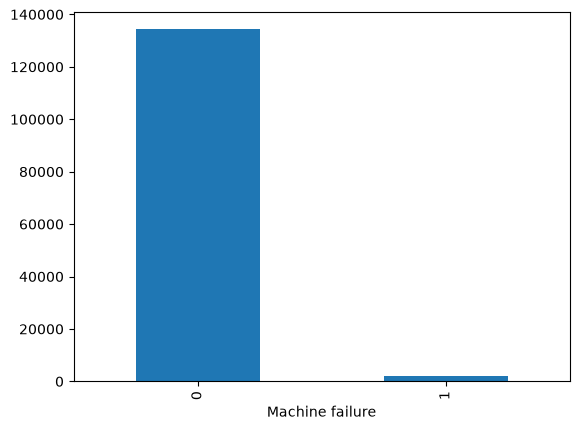

In [7]:
df['Machine failure'].value_counts().plot(kind='bar')

## There is clearly imbalance of data we can observe here 

## Step 2 : Data Cleaning

In [8]:
df.isna().sum()

id                         0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

## EDA

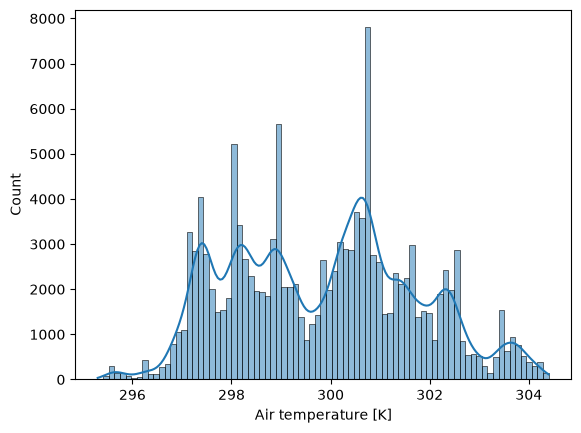

In [10]:
# Distribtuion of features like temperature, speed and tourque
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='Air temperature [K]',kde=True)

# Display the plot
plt.show()

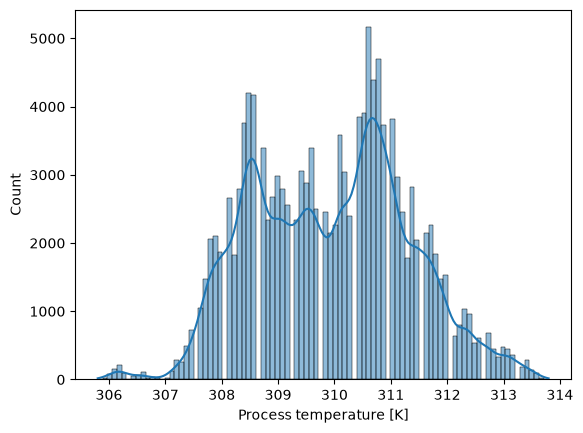

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='Process temperature [K]',kde=True)

# Display the plot
plt.show()

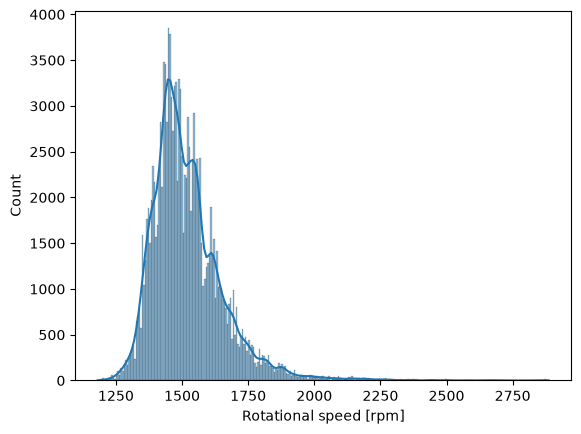

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='Rotational speed [rpm]', kde=True)

# Display the plot
plt.show()

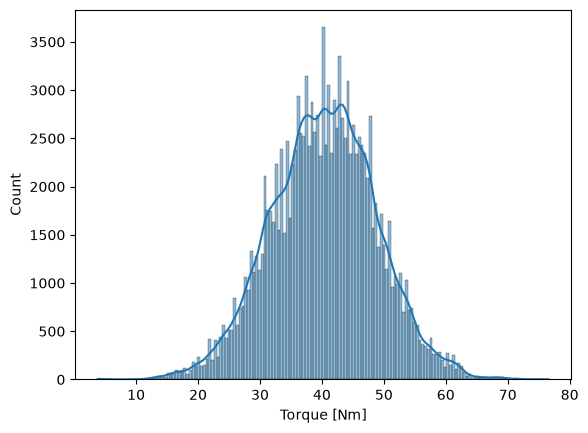

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='Torque [Nm]', kde=True)

# Display the plot
plt.show()

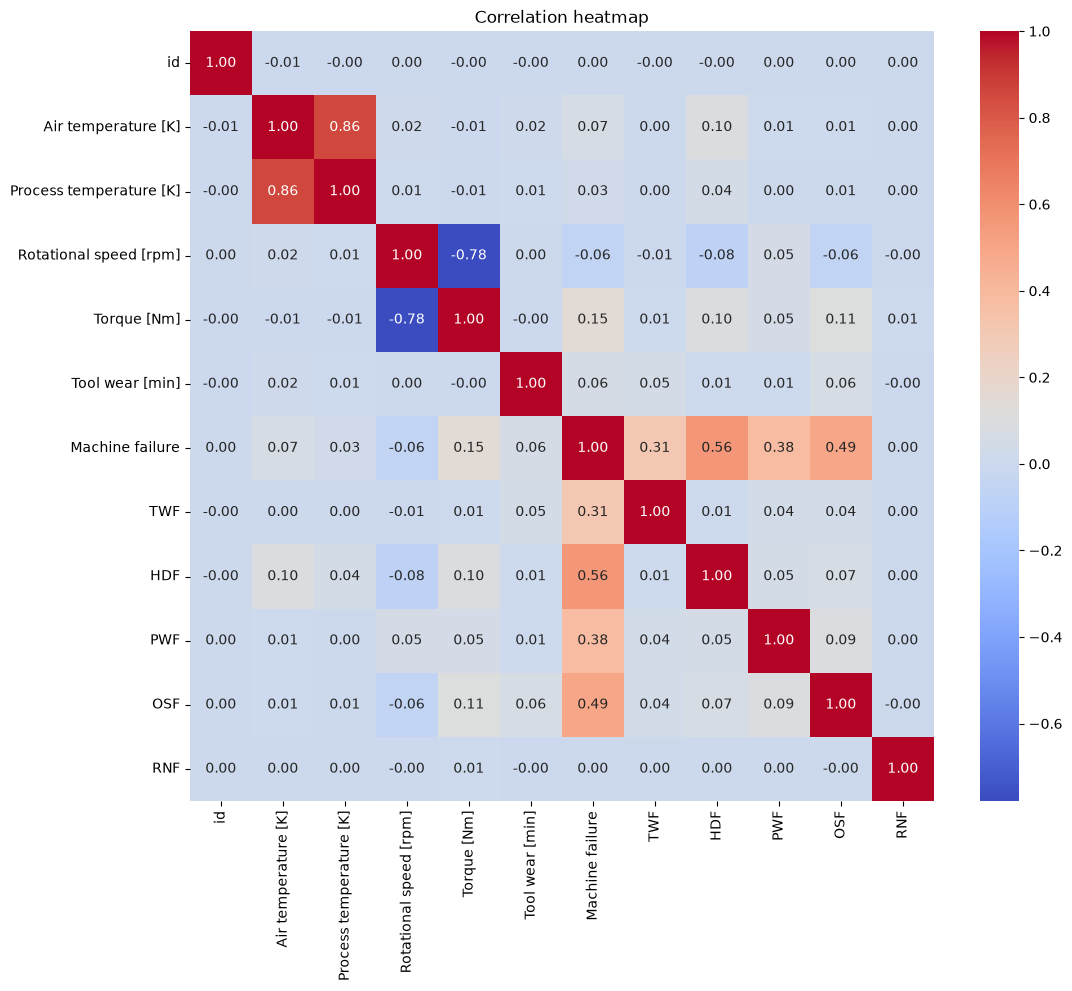

In [14]:
# Correlation 
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

## Analysis there is no correlation between Target feature and independent features. 

In [15]:
# Compare failed vs non-failed machine readings
df['Machine failure'].value_counts()

Machine failure
0    134281
1      2148
Name: count, dtype: int64

## Here 1 indicates failed that is 2148 times 
## 0 indicates non-failed that is 134281 times

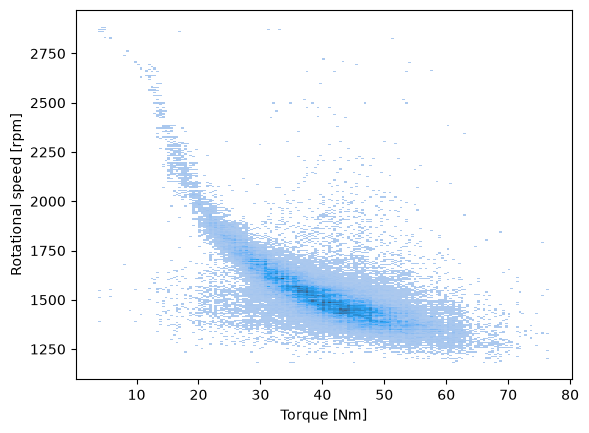

In [16]:
# Histogram Machine Failure vs HDF
import seaborn as sns
import matplotlib.pyplot as plt

# Create a 2D histogram using 'x' and 'y' columns
sns.histplot(data=df, x='Torque [Nm]', y='Rotational speed [rpm]')

# Display the plot
plt.show()


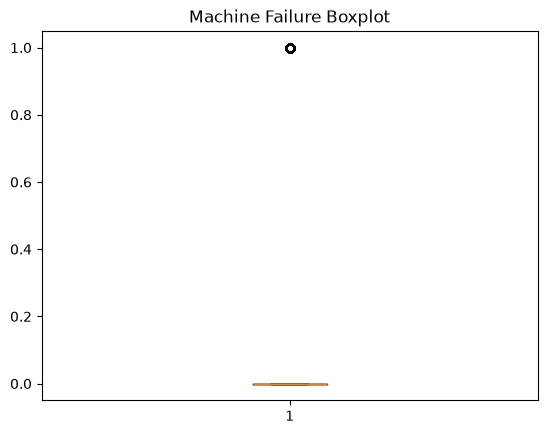

In [17]:
# Box plot
import matplotlib.pyplot as plt

plt.boxplot(df["Machine failure"])
plt.title("Machine Failure Boxplot")
plt.show()

## step 4 : Feature Engneering

In [18]:
df['Product ID'].unique()

<StringArray>
['L50096', 'M20343', 'L49454', 'L53355', 'M24050', 'M24300', 'L56736',
 'L55488', 'L56397', 'L55067',
 ...
 'M19631', 'L48200', 'M15360', 'M15965', 'L52495', 'L51832', 'L51811',
 'M18739', 'L50940', 'L48036']
Length: 9976, dtype: str

#### Product ID has too many unique features so we will apply Label Encoder 

In [19]:
df['Type'].unique()

<StringArray>
['L', 'M', 'H']
Length: 3, dtype: str

#### Type featurs has only 3 unique features so will apply Hot Encoder.

### Split Dataset Into Train ans Test.

In [20]:
X = df.drop(columns=['id','Machine failure'])
Y = df[['Machine failure']]

In [21]:
len(X.columns)

12

In [22]:
cat = list(X.select_dtypes(include='object').columns) 
con = list(X.select_dtypes(include='number').columns)
print(cat)
print(con)

['Product ID', 'Type']
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [23]:
cat_onehot = ['Type']
cat_label = ['Product ID']

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat_onehot),
                         ('con',num_pipe,con)]).set_output(transform='pandas')

from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(X,Y,random_state=21,train_size=0.75)

pre.fit(xtrain)

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

# Apply LabelEncoder separately
encoders = {}

for col in cat_label:
    # Impute missing values using training data's most frequent value
    most_frequent = xtrain[col].mode().iloc[0]

    train_col = xtrain[col].fillna(most_frequent).astype(str)
    test_col = xtest[col].fillna(most_frequent).astype(str)

    le = LabelEncoder()
    xtrain_pre[col] = le.fit_transform(train_col)

    # Handle categories in test data that weren't present in training
    mapping = {v: i for i, v in enumerate(le.classes_)}
    xtest_pre[col] = test_col.map(mapping).fillna(-1).astype(int)

    encoders[col] = le

In [76]:
xtrain['Product ID'].mode().iloc[0]

'L53257'

In [67]:
encoders

{'Product ID': LabelEncoder()}

In [25]:
xtrain_pre.columns

Index(['cat__Type_H', 'cat__Type_L', 'cat__Type_M', 'con__Air temperature [K]',
       'con__Process temperature [K]', 'con__Rotational speed [rpm]',
       'con__Torque [Nm]', 'con__Tool wear [min]', 'con__TWF', 'con__HDF',
       'con__PWF', 'con__OSF', 'con__RNF', 'Product ID'],
      dtype='str')

## Model Building

### Resampling Method

In [26]:
len(xtrain_pre)

102321

In [27]:
ytrain['Machine failure'].value_counts()

Machine failure
0    100713
1      1608
Name: count, dtype: int64

In [28]:
from imblearn.over_sampling import SMOTE,ADASYN

smote = SMOTE()

x_sampl_tr,y_sampl_tr = smote.fit_resample(xtrain_pre,ytrain)

In [29]:
len(x_sampl_tr)

201426

In [30]:
len(y_sampl_tr)

201426

In [31]:
y_sampl_tr['Machine failure'].value_counts()

Machine failure
0    100713
1    100713
Name: count, dtype: int64

In [32]:
x_sampl_tr.columns

Index(['cat__Type_H', 'cat__Type_L', 'cat__Type_M', 'con__Air temperature [K]',
       'con__Process temperature [K]', 'con__Rotational speed [rpm]',
       'con__Torque [Nm]', 'con__Tool wear [min]', 'con__TWF', 'con__HDF',
       'con__PWF', 'con__OSF', 'con__RNF', 'Product ID'],
      dtype='str')

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

In [34]:
dct = {
    'Logistic': LogisticRegression(),
    'DecisionTree': DecisionTreeClassifier(),
    'RandomForest': RandomForestClassifier(),
    'GradientBoosting': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier()
}

In [35]:
dct.items()

dict_items([('Logistic', LogisticRegression()), ('DecisionTree', DecisionTreeClassifier()), ('RandomForest', RandomForestClassifier()), ('GradientBoosting', GradientBoostingClassifier()), ('XGBoost', XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...))])

In [36]:
len(xtest_pre)

34108

In [37]:
import re

# Replace [, ], and < with an underscore
x_sampl_tr.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in x_sampl_tr.columns]
xtest_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xtest_pre.columns]

In [65]:
x_sampl_tr.columns

Index(['cat__Type_H', 'cat__Type_L', 'cat__Type_M', 'con__Air temperature _K_',
       'con__Process temperature _K_', 'con__Rotational speed _rpm_',
       'con__Torque _Nm_', 'con__Tool wear _min_', 'con__TWF', 'con__HDF',
       'con__PWF', 'con__OSF', 'con__RNF', 'Product ID'],
      dtype='str')

In [38]:
roc_scores = []

for name, model in dct.items() : # key value pairs
    # Fit the model
    model.fit(x_sampl_tr, y_sampl_tr['Machine failure'])
    #predict the results
    ypred_test = model.predict(xtest_pre)
    roc = roc_auc_score(ytest, ypred_test)
    roc_scores.append(round(roc,3))

print(roc_scores)

[0.888, 0.885, 0.883, 0.899, 0.888]


In [39]:
res = {
    'Name': list(dct.keys()),
    'ROC_Score': roc_scores
}
df_res = pd.DataFrame(res)
df_res.sort_values(by='ROC_Score',ascending=False)

,Name,ROC_Score
3,GradientBoosting,0.899
0,Logistic,0.888
4,XGBoost,0.888
1,DecisionTree,0.885
2,RandomForest,0.883


## We will be finalising Gradient Boost as the best model for deployment 

## HyperParameter Tuning 

In [40]:
from sklearn.ensemble import GradientBoostingClassifier

model = GradientBoostingClassifier(n_estimators=100,
                      max_depth=5,
                      learning_rate=0.01)
model.fit(x_sampl_tr,y_sampl_tr)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.01
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to c

In [41]:
model.score(x_sampl_tr,y_sampl_tr)

0.9372275674441234

In [42]:
model.score(xtest_pre,ytest)

0.995983347015363

In [43]:
params = {
    'n_estimators': [50,80,100],
    'max_depth': [4,5,6,7],
    'learning_rate':[0.01,0.02,0.1,0.2]
}

base_model = GradientBoostingClassifier()
from sklearn.model_selection import RandomizedSearchCV
rscv = RandomizedSearchCV(estimator=base_model, cv=3,param_distributions=params,scoring='f1_macro')
rscv.fit(x_sampl_tr,y_sampl_tr['Machine failure'])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoostingClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.02, ...], 'max_depth': [4, 5, ...], 'n_estimators': [50, 80, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit

In [44]:
rscv.best_params_

{'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.2}

In [45]:
rscv.best_score_

np.float64(0.9906611330068902)

In [46]:
best_gradient = rscv.best_estimator_
best_gradient

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.2
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",7
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [47]:
best_gradient.score(x_sampl_tr,y_sampl_tr)

0.9947424860742903

In [48]:
best_gradient.score(xtest_pre,ytest)

0.9940776357452797

## Evaluation Metrics

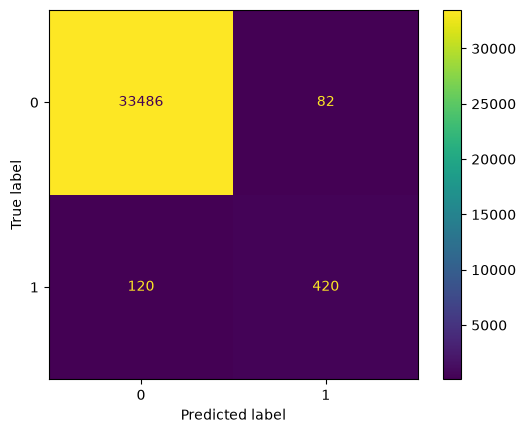

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay,classification_report
ConfusionMatrixDisplay.from_estimator(best_gradient,xtest_pre,ytest)

In [50]:
ypreds = best_gradient.predict(xtest_pre)
print(classification_report(ytest,ypreds))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     33568
           1       0.84      0.78      0.81       540

    accuracy                           0.99     34108
   macro avg       0.92      0.89      0.90     34108
weighted avg       0.99      0.99      0.99     34108



In [52]:
from sklearn.metrics import roc_curve,auc
fpr,tpr,thresholds = roc_curve(ytest,ypreds)

auc_scores = auc(fpr,tpr)
auc_scores

0.8876674875542844

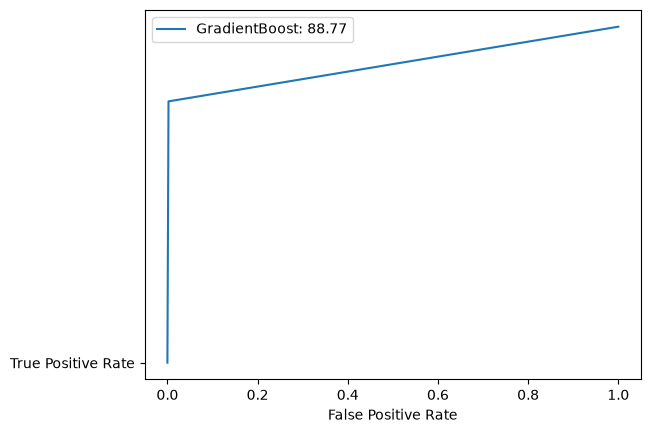

In [53]:
import matplotlib.pyplot as plt
plt.plot(fpr,tpr,label=f"GradientBoost: {auc_scores*100:.2f}")
plt.xlabel("False Positive Rate")
plt.plot("True Positive Rate")
plt.legend()
plt.show()

## AUC is above 80%. We can finalise this model

In [54]:
import joblib
joblib.dump(best_gradient, "model.joblib")
joblib.dump(pre, "pipeline.joblib")

['pipeline.joblib']

## Picking Up Sample Data Out of Sample Prediction

In [55]:
xnew = pd.read_csv(r"D:\ML\DataSets\test (1).csv")
xnew.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
0,136429,L50896,L,302.3,311.5,1499,38.0,60,0,0,0,0,0
1,136430,L53866,L,301.7,311.0,1713,28.8,17,0,0,0,0,0
2,136431,L50498,L,301.3,310.4,1525,37.7,96,0,0,0,0,0
3,136432,M21232,M,300.1,309.6,1479,47.6,5,0,0,0,0,0
4,136433,M19751,M,303.4,312.3,1515,41.3,114,0,0,0,0,0


In [57]:
pipeline_loaded = joblib.load("pipeline.joblib")
xnew_pre = pipeline_loaded.transform(xnew)
xnew_pre.head()

,cat__Type_H,cat__Type_L,cat__Type_M,con__Air temperature [K],con__Process temperature [K],con__Rotational speed [rpm],con__Torque [Nm],con__Tool wear [min],con__TWF,con__HDF,con__PWF,con__OSF,con__RNF
0,0.0,1.0,0.0,1.310113,1.126401,-0.154591,-0.275148,-0.693995,-0.040554,-0.071193,-0.048992,-0.063661,-0.048183
1,0.0,1.0,0.0,0.987934,0.765708,1.385529,-1.356853,-1.366151,-0.040554,-0.071193,-0.048992,-0.063661,-0.048183
2,0.0,1.0,0.0,0.773149,0.332876,0.032526,-0.310421,-0.131261,-0.040554,-0.071193,-0.048992,-0.063661,-0.048183
3,0.0,0.0,1.0,0.128792,-0.244233,-0.298528,0.853588,-1.553729,-0.040554,-0.071193,-0.048992,-0.063661,-0.048183
4,0.0,0.0,1.0,1.900773,1.703511,-0.039442,0.112855,0.150106,-0.040554,-0.071193,-0.048992,-0.063661,-0.048183


In [62]:
x_sampl_tr.columns

Index(['cat__Type_H', 'cat__Type_L', 'cat__Type_M', 'con__Air temperature _K_',
       'con__Process temperature _K_', 'con__Rotational speed _rpm_',
       'con__Torque _Nm_', 'con__Tool wear _min_', 'con__TWF', 'con__HDF',
       'con__PWF', 'con__OSF', 'con__RNF', 'Product ID'],
      dtype='str')

In [63]:
xnew_pre.columns = [re.sub(r'[\[\]<]', '_', str(col)) for col in xnew_pre.columns]

In [66]:
xnew_pre.columns

Index(['cat__Type_H', 'cat__Type_L', 'cat__Type_M', 'con__Air temperature _K_',
       'con__Process temperature _K_', 'con__Rotational speed _rpm_',
       'con__Torque _Nm_', 'con__Tool wear _min_', 'con__TWF', 'con__HDF',
       'con__PWF', 'con__OSF', 'con__RNF'],
      dtype='str')

In [69]:
test_col2=xnew_pre['Product ID'].fillna(most_frequent).astype(str)
xnew_pre['Product ID'] = test_col2.map(mapping).fillna(-1).astype(int)

In [70]:
xnew_pre.columns

Index(['cat__Type_H', 'cat__Type_L', 'cat__Type_M', 'con__Air temperature _K_',
       'con__Process temperature _K_', 'con__Rotational speed _rpm_',
       'con__Torque _Nm_', 'con__Tool wear _min_', 'con__TWF', 'con__HDF',
       'con__PWF', 'con__OSF', 'con__RNF', 'Product ID'],
      dtype='str')

In [71]:
model_loaded = joblib.load("model.joblib")
model_prediction = model_loaded.predict(xnew_pre)
model_prediction

array([0, 0, 0, ..., 0, 0, 0], shape=(90954,))

In [73]:
xnew["Model Prediction"] = model_prediction

In [74]:
xnew.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,Model Prediction
0,136429,L50896,L,302.3,311.5,1499,38.0,60,0,0,0,0,0,0
1,136430,L53866,L,301.7,311.0,1713,28.8,17,0,0,0,0,0,0
2,136431,L50498,L,301.3,310.4,1525,37.7,96,0,0,0,0,0,0
3,136432,M21232,M,300.1,309.6,1479,47.6,5,0,0,0,0,0,0
4,136433,M19751,M,303.4,312.3,1515,41.3,114,0,0,0,0,0,0


In [75]:
xnew.to_csv("ModelPredictionResults.csv",index=False)